In [325]:
import sys
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from hcipy import * 
from psfGenerator import PsfGenerator
sys.path.append(os.path.abspath(os.path.join(os.path.dirname('adc_sims'), '..')))
from slicing_class import adcFitter2

In [557]:
## part 1: finding the response
wavelength = 764E-9
bw = 126E-9
wavelength_normalized = wavelength / 656E-9
bw_normalized = bw / wavelength
grating_angle = 28
grating_freq = 47 

ADC = adcFitter2(wavelength=wavelength,bandwidth=bw,grating_angle=grating_angle,grating_freq=grating_freq,snr_threshold=2.6,speckle_window=60)
PsfGen = PsfGenerator(center_wavelength=wavelength_normalized,bandwidth=bw_normalized, focal_sampling=6, focal_extent=60,grating_angle=grating_angle, fx=grating_freq, fy = grating_freq, mask=True)

least-squares solution: (4.1722782926034725,-8.24718879124932)
Estimated dispersion direction -116.83498949760971°
Estimated dispersion magnitude 9.242512056223598


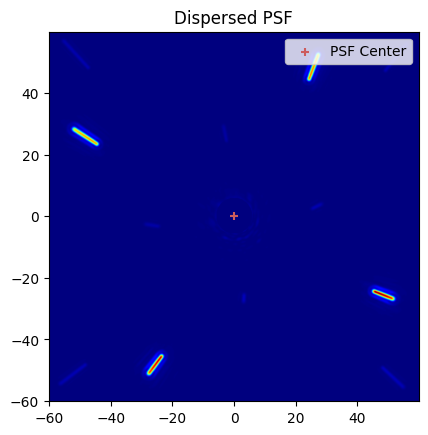

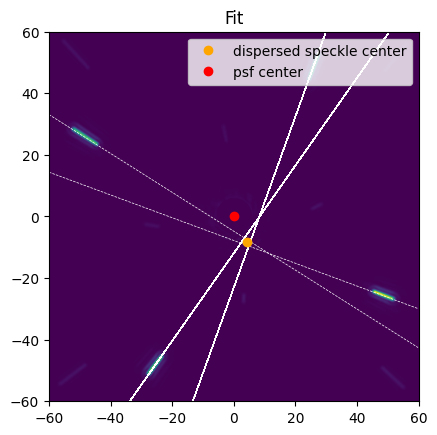

In [327]:
#sample PSF with dispersion measurement
# disp_x = np.random.rand() * 0.1
# disp_y = np.random.rand() * 0.1

# #these two parameters define the atmospheric dispersion vector
# disp_mag = np.sqrt(disp_x**2 + disp_y**2)
# disp_ang = np.atan(disp_y / disp_x)

disp = 0.08
ang = 90-27

num_photons = 1E9
#psf = PsfGen.noisy_turbulent_psf(magnitude_x=disp_x,magnitude_y=disp_y,num_photons=num_photons,ptv=0)
psf = PsfGen.polar_psf(magnitude = disp,orientation = ang,num_photons=num_photons)

true_center = np.array([0,0]) #we can worry about how well we can estimate this later


imshow_field(psf,cmap='jet')
plt.scatter(true_center[0],true_center[1],marker='+',color='indianred',label='PSF Center')
plt.legend()
plt.title('Dispersed PSF')

plt.figure()
est = ADC.speckles_dxdy(psf,plotted=True,printed=True)
plt.title('Fit')
plt.show()

now we need to define the ADC dispersion vector
 - to do this we need to know the response - the /orthogonal/ response, to be precise
 - but this is something we don't really know with the simulation, since the ADC isn't actually moving. therefore, the ADC response will be calibrated to match something similar to the real system
 - in the calibrations from feb 20, the shearing response changed the magnitude of the dispersion vector by 1.3 pixels/degree shear
 - we'll assume that the orientation is 1:1 degrees/degrees - this can be changed once i understand the real behavior better

In [328]:
#these two quantities will define the ADC behavior, and will be used to create the ADC dispersion vector
adc_shear = 0
adc_rot = 0

#this is the actual ADC dispersion vector
adc_dx = adc_shear * np.cos(np.radians(adc_rot))
adc_dy = adc_shear * np.sin(np.radians(adc_rot))

#the ADC NCPC orthogonal response
m00 = 1/1.3 #degrees/pixel
m01 = 1 #degrees/degree 

notes:
- the slope of the dx plot is the same as the slope of the shear plot when the speckles are orthogonal to the axis of dispersion
- there is a degeneracy between positive and negative shear angles when we only measure the length of the dispersion vector. this is why the direction becomes especially important.

Now let's look at what happens when the dispersion axis is not exactly orthogonal:

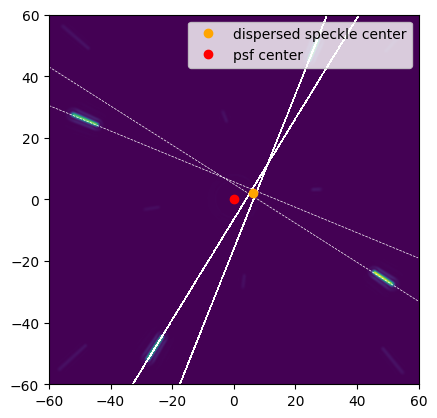

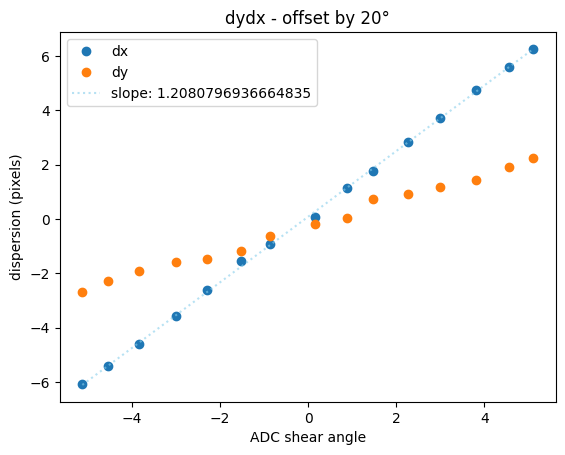

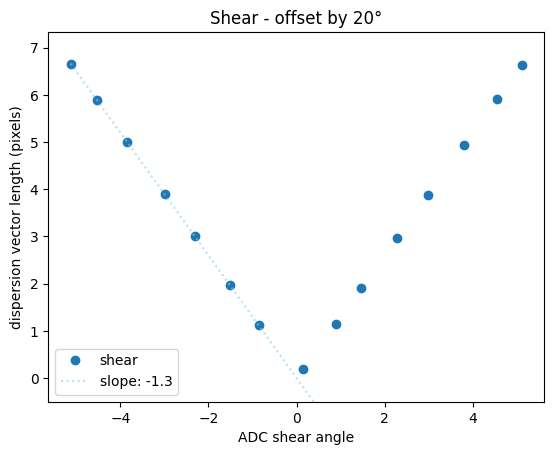

In [329]:
disps = np.linspace(-0.06,0.06,15) #same overall magnitude but we're gonna point it in different directions
dir = 20 #degrees - dispersion vector orientation
disps_x = np.cos(np.radians(dir)) * disps
disps_y = np.sin(np.radians(dir)) * disps

num_photons = 1E12

dx_list = []
dy_list = []

for i, disp in enumerate(disps_x):
    psf = PsfGen.psf(magnitude_x=disp,magnitude_y=disps_y[i])
    est = ADC.speckles_dxdy(psf,plotted=False,printed=False)
    dx_list.append(est[0])
    dy_list.append(est[1])

ADC.speckles_dxdy(psf,plotted=True,printed=False)
imshow_field(psf)
plt.show()

dx_list = np.array(dx_list)
dy_list = np.array(dy_list)

#now convert these dx and dy estimates into ADC shear and rotation angles, ASSUMING THE DISPERSION AXIS IS ORTHOGONAL TO THE ADC AXIS
sq = np.sqrt(np.sum(np.vstack((dx_list**2,dy_list**2)),axis=0)) #magnitude of each dispersion vector
ang = np.arctan2(dy_list,dx_list) #orientation of each dispersion vector - this will error out if the angle is 90°, which it is in this case

adc_shear = m00 * sq
adc_shear[:7] = -adc_shear[:7]
adc_rot = m01 * ang

m1, b1 = np.polyfit(adc_shear,dx_list,deg=1)

plt.plot(adc_shear,dx_list,'o',label='dx')
plt.plot(adc_shear,dy_list,'o',label='dy')
linepoints = b1 + m1 * adc_shear
plt.plot(adc_shear,linepoints,label=f'slope: {m1}',linestyle='dotted',color='skyblue',alpha=0.6)
plt.xlabel('ADC shear angle')
plt.ylabel('dispersion (pixels)')
plt.title(f'dydx - offset by {dir}°')
plt.legend()
plt.show()

m2, b2 = np.polyfit(adc_shear[:7],sq[:7],deg=1)

plt.figure()
plt.plot(adc_shear,sq,'o',label='shear')
linepoints2 = b2 + m2 * adc_shear
plt.plot(adc_shear,linepoints2,label=f'slope: {m2}',linestyle='dotted',color='skyblue',alpha=0.6)
plt.xlabel('ADC shear angle')
plt.ylabel('dispersion vector length (pixels)')
plt.title(f'Shear - offset by {dir}°')
plt.ylim(bottom=-0.5)
plt.legend()
plt.show()

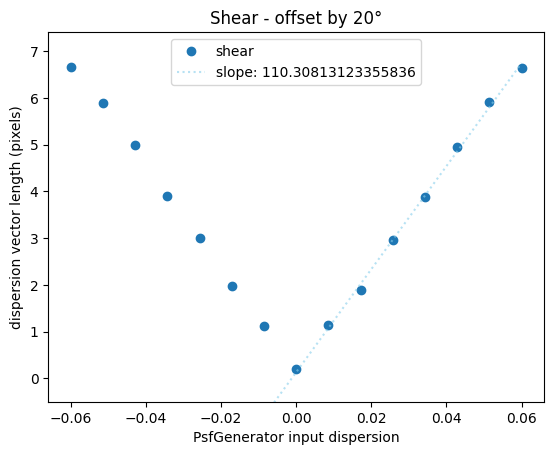

In [330]:
#this will become important for when we try to simulate the controller
m3, b3 = np.polyfit(disps[8:],sq[8:],deg=1)
m02 = m3 #pixels/arb. dispersion input

plt.figure()
plt.plot(disps,sq,'o',label='shear')
linepoints3 = b3 + m3 * disps
plt.plot(disps,linepoints3,label=f'slope: {m3}',linestyle='dotted',color='skyblue',alpha=0.6)
plt.xlabel('PsfGenerator input dispersion')
plt.ylabel('dispersion vector length (pixels)')
plt.title(f'Shear - offset by {dir}°')
plt.ylim(bottom=-0.5)
plt.legend()
plt.show()

In [331]:
#let's plot how the slope of the dx line changes based on the offset between the ADC axis and the dispersion axis
disps = np.linspace(-0.06,0.06,15) #same overall magnitude but we're gonna point it in different directions
dir = 90 #degrees - dispersion vector orientation
disps_x = np.cos(np.radians(dir)) * disps
disps_y = np.sin(np.radians(dir)) * disps

num_photons = 1E12

dirs = np.linspace(0,90,20)
dx_slopes = []

for j, dir in enumerate(dirs):
    disps = np.linspace(-0.06,0.06,15) #same overall magnitude but we're gonna point it in different directions
    disps_x = np.cos(np.radians(dir)) * disps
    disps_y = np.sin(np.radians(dir)) * disps


    dx_list = []
    dy_list = []

    for i, disp in enumerate(disps_x):
        psf = PsfGen.psf(magnitude_x=disp,magnitude_y=disps_y[i])
        est = ADC.speckles_dxdy(psf,plotted=False,printed=False)
        dx_list.append(est[0])
        dy_list.append(est[1])

    dx_list = np.array(dx_list)
    dy_list = np.array(dy_list)

    #now convert these dx and dy estimates into ADC shear and rotation angles, ASSUMING THE DISPERSION AXIS IS ORTHOGONAL TO THE ADC AXIS
    sq = np.sqrt(np.sum(np.vstack((dx_list**2,dy_list**2)),axis=0)) #magnitude of each dispersion vector
    ang = np.arctan2(dy_list,dx_list) #orientation of each dispersion vector - this will error out if the angle is 90°, which it is in this case

    adc_shear = m00 * sq
    adc_shear[:7] = -adc_shear[:7]
    adc_rot = m01 * ang

    m1, b1 = np.polyfit(adc_shear,dx_list,deg=1)
    dx_slopes.append(m1)


[ 0.99131923 -0.03497676  1.29882837]


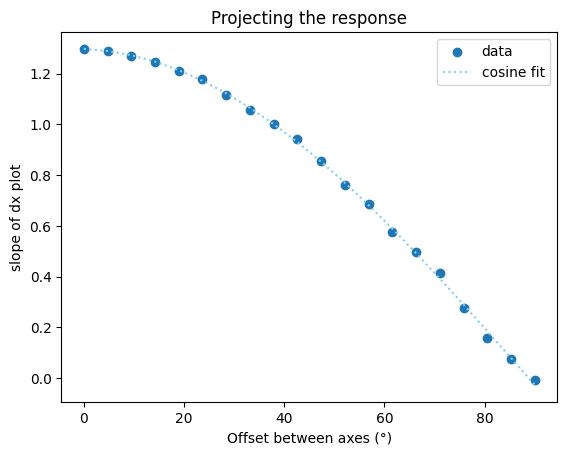

In [332]:
def cosine(angs,stretch,shift,amp):
    angs = np.radians(angs)
    return np.cos(angs * stretch - shift) * amp


dx_slopes = np.array(dx_slopes)

popt, *_ = curve_fit(cosine,dirs,dx_slopes)
print(popt)
fit = cosine(dirs,*popt)

# m, b = np.polyfit(dirs,dx_slopes,deg=1)
# linepoints = b + m * dirs

plt.figure()
plt.scatter(dirs,dx_slopes,label='data')
plt.plot(dirs,fit,linestyle='dotted',color='skyblue',label='cosine fit')
#plt.plot(dirs,linepoints,linestyle='dotted',color='skyblue',alpha=0.6,label=f'slope: {m}')
plt.xlabel('Offset between axes (°)')
plt.ylabel('slope of dx plot')
plt.title('Projecting the response')
plt.legend()
plt.show()

In [333]:
#same thing except it's the speckle angle pairs instead of dx that we're comparing against
disps = np.linspace(-0.06,0.06,15) #same overall magnitude but we're gonna point it in different directions
dir = 90 #degrees - dispersion vector orientation
disps_x = np.cos(np.radians(dir)) * disps
disps_y = np.sin(np.radians(dir)) * disps

num_photons = 1E12

dirs = np.linspace(0,90,20)
pair_slopes24 = []

for j, dir in enumerate(dirs):
    disps = np.linspace(-0.06,0.06,15) #same overall magnitude but we're gonna point it in different directions
    disps_x = np.cos(np.radians(dir)) * disps
    disps_y = np.sin(np.radians(dir)) * disps


    pair24 = []
    dx_list = []
    dy_list = []

    for i, disp in enumerate(disps_x):
        psf = PsfGen.psf(magnitude_x=disp,magnitude_y=disps_y[i])
        est = ADC.speckles_dxdy(psf,plotted=False,printed=False)
        est1 = ADC.speckle_pairs(ADC.all_speckle_angles(psf))
        pair24.append(est1[1])
        dx_list.append(est[0])
        dy_list.append(est[1])

    dx_list = np.array(dx_list)
    dy_list = np.array(dy_list)
    pair24 = np.array(pair24)

    #now convert these dx and dy estimates into ADC shear and rotation angles, ASSUMING THE DISPERSION AXIS IS ORTHOGONAL TO THE ADC AXIS
    sq = np.sqrt(np.sum(np.vstack((dx_list**2,dy_list**2)),axis=0)) #magnitude of each dispersion vector
    ang = np.arctan2(dy_list,dx_list) #orientation of each dispersion vector - this will error out if the angle is 90°, which it is in this case

    adc_shear = m00 * sq
    adc_shear[:7] = -adc_shear[:7]
    adc_rot = m01 * ang

    m1, b1 = np.polyfit(adc_shear,pair24,deg=1)
    pair_slopes24.append(m1)


[ 0.99842971  1.09192649 -2.71262581]


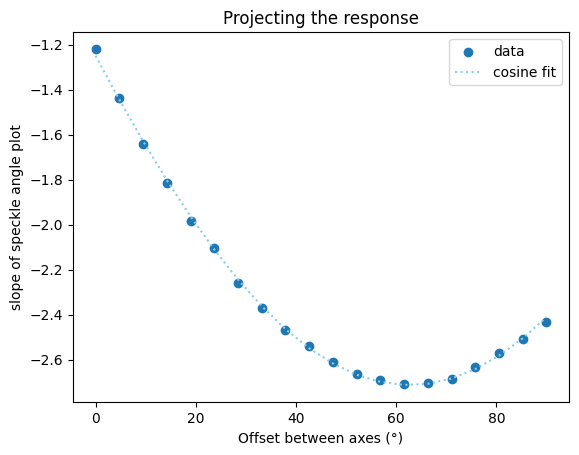

In [334]:
popt, *_ = curve_fit(cosine,dirs,pair_slopes24)
print(popt)
fit = cosine(dirs,*popt)

plt.figure()
plt.scatter(dirs,pair_slopes24,label='data')
plt.plot(dirs,fit,linestyle='dotted',color='skyblue',label='cosine fit')
plt.xlabel('Offset between axes (°)')
plt.ylabel('slope of speckle angle plot')
plt.title('Projecting the response')
plt.legend()
plt.show()

That's pretty definitive - the response of the speckles changes with the cosine of the angle between the dispersion axis and the ADC axis. The amplitude of the cosine will depend on the separation and waveband of the speckles. 

But, if I instead do the control using the magnitude and orientation of the dispersion, it shouldn't matter what the relative orientations are, since i'm measuring it in the 2D image plane instead of just along one axis

injected dispersion dx: [0.01740033] dy: [0.03415008]
est dispersion 4.237351494219731 pixels
est disp axis 64.56149567895675°
est ADC shear angle: -3.259501149399793°
est ADC rot angle: -64.56149567895675°
remaining dispersion: [-8.62471457e-05]
remaining axis offset -1.5614956789567458


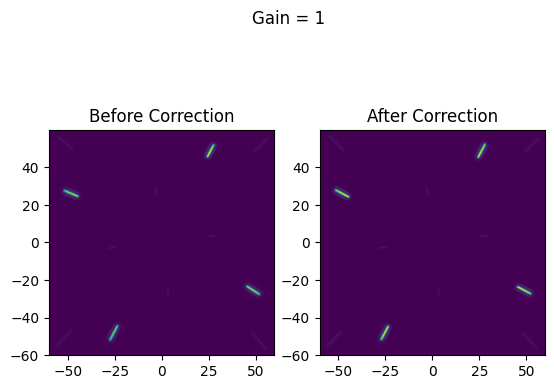

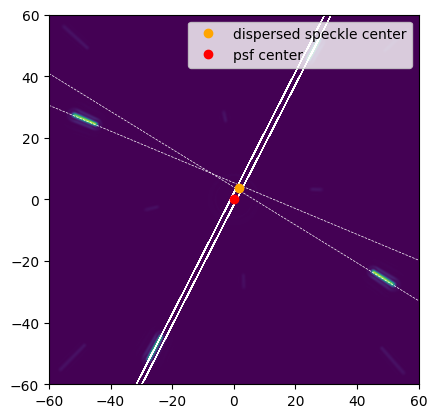

In [335]:
#one single iteration with a gain of one, before I put it in an integrator
#the response
m00 = 1/1.3 #degrees/pixel
m01 = 1 #degrees/degree 
m02 = m3 #pixels/arb. dispersion input

#set up dispersed PSF
disps =  np.abs(np.random.randn(1))*.08#-0.08 + np.abs(np.random.randn(1))*.02
dir = 90-27 #degrees - dispersion vector orientation
disps_x = np.cos(np.radians(dir)) * disps
disps_y = np.sin(np.radians(dir)) * disps
print(f'injected dispersion dx: {disps_x} dy: {disps_y}')

psf = PsfGen.psf(magnitude_x=disps_x,magnitude_y=disps_y)

fig, ax = plt.subplots(1,2)
imshow_field(psf,ax=ax[0])
ax[0].set_title('Before Correction')

#now try and measure it
plt.figure()
est_x, est_y = ADC.speckles_dxdy(psf,plotted=True,printed=False)
sq = np.sqrt(est_x**2+est_y**2)
ang = np.degrees(np.arctan2(est_y,est_x))
print(f'est dispersion {sq} pixels')
print(f'est disp axis {ang}°')

#calculate how much to move ADCs
#get the correct quadrant
if est_x >0 and est_y>0:
    sign = -1
elif est_x <0 and est_y>0:
    sign = 1
elif est_x <0 and est_y<0:
    sign = 1
else: sign = -1
    
shear_est = sign * m00 * sq
rot_est = sign * ang #this is 1:1, measuring from the x-axis in this simulation (irl it's the y-axis)
print(f'est ADC shear angle: {shear_est}°')
print(f'est ADC rot angle: {rot_est}°')

#integrate (gain of one)
disps =  disps + shear_est * 1/m00 * 1/m02 #deg * px/deg * arb./px
dir = dir + rot_est
disps_x = np.cos(np.radians(dir)) * disps
disps_y = np.sin(np.radians(dir)) * disps
psf = PsfGen.psf(magnitude_x=disps_x,magnitude_y=disps_y)
print(f'remaining dispersion: {disps}')
print(f'remaining axis offset {dir}')

imshow_field(psf,ax=ax[1])
ax[1].set_title('After Correction')
fig.suptitle('Gain = 1')
plt.show()

### Closed-loop correction using this new approach

injected dispersion dx: [-0.08668787] dy: [0.00236311]


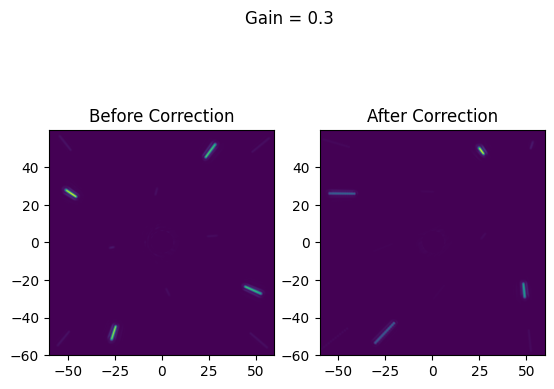

In [336]:
#now a full iterative thing with gain:
induced_disp = -np.abs(np.random.randn(1))*.05
induced_dir = -45 #degrees - dispersion vector orientation
disps_x = np.cos(np.radians(dir)) * induced_disp
disps_y = np.sin(np.radians(dir)) * induced_disp
print(f'injected dispersion dx: {disps_x} dy: {disps_y}')
shear_est = 0
rot_est = 0

num_iterations = 10
gain = 0.3

disp_tracker = []
ang_tracker = []

psf = PsfGen.noisy_turbulent_psf(magnitude_x=disps_x,magnitude_y=disps_y,num_photons=1E8)
fig, ax = plt.subplots(1,2)
imshow_field(psf,ax=ax[0])
ax[0].set_title('Before Correction')

for i in range(num_iterations):
    est_x, est_y = ADC.speckles_dxdy(psf,plotted=False,printed=False)
    sq = np.sqrt(est_x**2+est_y**2)
    ang = np.degrees(np.arctan2(est_y,est_x))

    if est_x >0 and est_y>0:
        sign = -1
    elif est_x <0 and est_y>0:
        sign = 1
    elif est_x <0 and est_y<0:
        sign = 1
    else: sign = -1
        
    shear_est += sign * m00 * sq * gain
    rot_est += sign * ang * gain #this is 1:1, measuring from the x-axis in this simulation (irl it's the y-axis)
    # print(f'est ADC shear angle: {shear_est}°')
    # print(f'est ADC rot angle: {rot_est}°')

    #integrate (gain of one)
    disps = induced_disp + shear_est * 1/m00 * 1/m02 #deg * px/deg * arb./px
    dir = induced_dir + rot_est
    disps_x = np.cos(np.radians(dir)) * disps
    disps_y = np.sin(np.radians(dir)) * disps
    # print(f'remaining dispersion: {disps}')
    # print(f'remaining axis offset {dir}')
    disp_tracker.append(disps)
    ang_tracker.append(dir)

    psf = PsfGen.noisy_turbulent_psf(magnitude_x=disps_x,magnitude_y=disps_y,num_photons=1E8)

disp_tracker = np.array(disp_tracker) * m02 * m00

imshow_field(psf,ax=ax[1])
ax[1].set_title('After Correction')
fig.suptitle(f'Gain = {gain}')
plt.show()

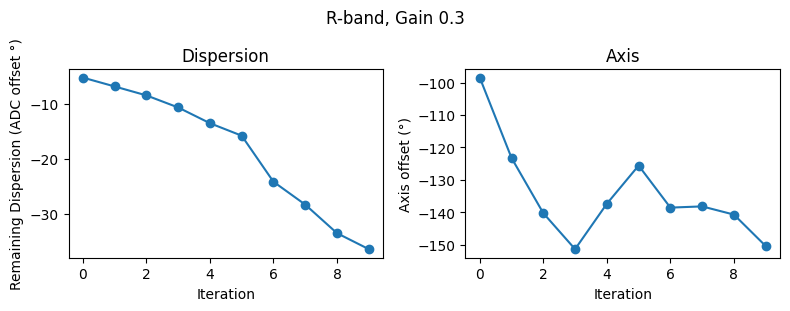

In [337]:
#plot the behavior as it goes through the iterations

fig, ax = plt.subplots(1,2,figsize=(8,3))
ax[0].plot(disp_tracker,'o-')
ax[0].set_title('Dispersion')
ax[0].set_xlabel('Iteration')
ax[0].set_ylabel('Remaining Dispersion (ADC offset °)')

ax[0].set_box_aspect(0.6)

ax[1].plot(ang_tracker,'o-')
ax[1].set_title('Axis')
ax[1].set_xlabel('Iteration')
ax[1].set_ylabel('Axis offset (°)')
ax[1].set_box_aspect(0.6)

fig.suptitle(f'R-band, Gain {gain}')
fig.tight_layout()
plt.show()

In [338]:
print(disp_tracker[2])
print(ang_tracker[2])

[-8.48197332]
-140.2737895202843


I need to understand if the method I'm using gives me the level of precision that I need. To do this, make the loop run for much longer than it needs to converge and look at the variance of the points after the point of convergence

injected dispersion dx: -0.006166571496442598 dy: -0.08978849255878651


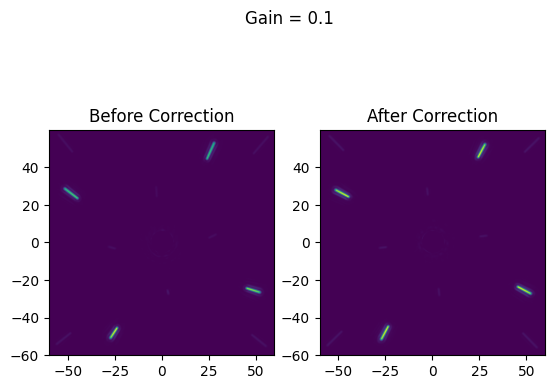

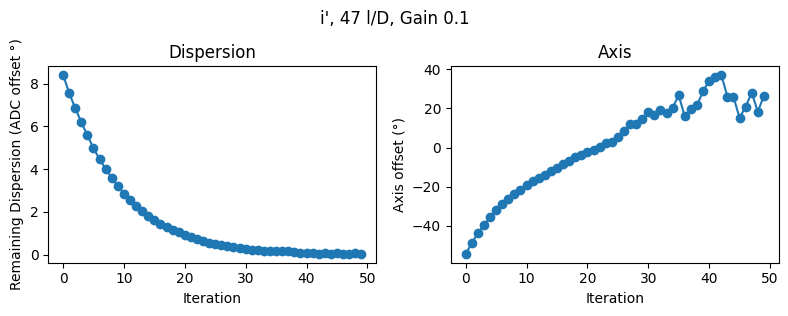

In [349]:
#now a full iterative thing with gain:
induced_disp =  .09
induced_dir = -45 #degrees - dispersion vector orientation
disps_x = np.cos(np.radians(dir)) * induced_disp
disps_y = np.sin(np.radians(dir)) * induced_disp
print(f'injected dispersion dx: {disps_x} dy: {disps_y}')
shear_est = 0
rot_est = 0

num_iterations = 50
gain = 0.1

disp_tracker = []
ang_tracker = []

psf = PsfGen.noisy_turbulent_psf(magnitude_x=disps_x,magnitude_y=disps_y,num_photons=1E8)
fig, ax = plt.subplots(1,2)
imshow_field(psf,ax=ax[0])
ax[0].set_title('Before Correction')

for i in range(num_iterations):
    est_x, est_y = ADC.speckles_dxdy(psf,plotted=False,printed=False)
    sq = np.sqrt(est_x**2+est_y**2)
    ang = np.degrees(np.arctan2(est_y,est_x))

    if est_x >0 and est_y>0:
        sign = -1
    elif est_x <0 and est_y>0:
        sign = 1
    elif est_x <0 and est_y<0:
        sign = 1
    else: sign = -1
        
    shear_est += sign * m00 * sq * gain
    rot_est += sign * ang * gain #this is 1:1, measuring from the x-axis in this simulation (irl it's the y-axis)
    # print(f'est ADC shear angle: {shear_est}°')
    # print(f'est ADC rot angle: {rot_est}°')

    #integrate (gain of one)
    disps = induced_disp + shear_est * 1/m00 * 1/m02 #deg * px/deg * arb./px
    dir = induced_dir + rot_est
    disps_x = np.cos(np.radians(dir)) * disps
    disps_y = np.sin(np.radians(dir)) * disps
    # print(f'remaining dispersion: {disps}')
    # print(f'remaining axis offset {dir}')
    disp_tracker.append(disps)
    ang_tracker.append(dir)

    psf = PsfGen.noisy_turbulent_psf(magnitude_x=disps_x,magnitude_y=disps_y,num_photons=1E8)

disp_tracker = np.array(disp_tracker) * m02 * m00

imshow_field(psf,ax=ax[1])
ax[1].set_title('After Correction')
fig.suptitle(f'Gain = {gain}')
plt.show()

fig, ax = plt.subplots(1,2,figsize=(8,3))
ax[0].plot(disp_tracker,'o-')
ax[0].set_title('Dispersion')
ax[0].set_xlabel('Iteration')
ax[0].set_ylabel('Remaining Dispersion (ADC offset °)')

ax[0].set_box_aspect(0.6)

ax[1].plot(ang_tracker,'o-')
ax[1].set_title('Axis')
ax[1].set_xlabel('Iteration')
ax[1].set_ylabel('Axis offset (°)')
ax[1].set_box_aspect(0.6)

fig.suptitle(f'i\', 47 l/D, Gain {gain}')
fig.tight_layout()
plt.show()

ADCs start at 50.5 and 49.5
injected residual dispersion dx: 0.05142300877492315 dy: 0.061283555449518246
corresponds to shear of 3.394096345647949 and orientation of 50°
est dispersion 8.646112735215846 pixels
est disp axis 50.38215797552405°
est ADC shear angle: 3.3254279750830174°
est axis: 50.38215797552405
est axis offset: 0.38215797552405206°
remaining dispersion: 0.05648556102294254
remaining axis offset -0.11464739265721846°

est dispersion 6.3125809150245615 pixels
est disp axis -1.0385372795570442°
est ADC shear angle: 2.427915736547908°
est axis: -1.0385372795570442
est axis offset: -51.03853727955705°
remaining dispersion: 0.03931752224529675
remaining axis offset 15.196913791209901°

est dispersion 4.569315011060156 pixels
est disp axis 15.096912918969858°
est ADC shear angle: 1.7574288504077522°
est axis: 15.096912918969858
est axis offset: -34.903087081030144°
remaining dispersion: 0.026890564341208734
remaining axis offset 25.66783991551894°

est dispersion 3.0814596737

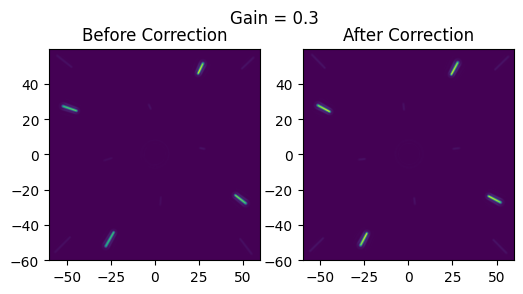

In [ ]:
#let's put everything in terms of dadc1 and dadc2
######## NOT WORKING, AXIS IS WRONG #################
#for simplicity i'm going to assume that each ADC contributes half of the magnitude, and that the orientation is 1:1 with the average position between adc1 and adc2
gain =0.3
num_iterations = 20
disp_tracker = []
ang_tracker = []
dadc1_tracker = []
dadc2_tracker = []

#delta ADC angle
dadc1 = 0
dadc2 = 0

#nominal ADC params - this is where the ADC starts based on the lookup table.
adc_axis = 50 #highest this number ever gets 
adc_shear = 0.5 #a reasonable number

#stageADC configurations
sadc1 = adc_axis + adc_shear
sadc2 = adc_axis - adc_shear 
print(f'ADCs start at {sadc1} and {sadc2}')

#scale factors to convert from simulation space to ADC angle space
m00 = 1/1.3/2 #adc1/2 offset degrees/pixel
m02 = m3 #pixels/arb. dispersion input
m01 = 1 #degrees adc axis/degrees dispersion vector axis 

#set up PSF with residual dispersion
induced_disp =  0.08 #residual dispersion magnitude
induced_dir = adc_axis
 #offset from nominal adc axis
disps_x = np.cos(np.radians(induced_dir)) * induced_disp
disps_y = np.sin(np.radians(induced_dir)) * induced_disp
print(f'injected residual dispersion dx: {disps_x} dy: {disps_y}')
print(f'corresponds to shear of {induced_disp * m02*m00} and orientation of {induced_dir}°')

psf = PsfGen.psf(magnitude_x=disps_x,magnitude_y=disps_y)

fig, ax = plt.subplots(1,2,figsize=(6,3))
imshow_field(psf,ax=ax[0])
ax[0].set_title('Before Correction')

#now try and measure it
for n in range(num_iterations):
    est_x, est_y = ADC.speckles_dxdy(psf,plotted=False,printed=False)
    sq = np.sqrt(est_x**2+est_y**2)
    ang = np.degrees(np.arctan2(est_y,est_x))
    print(f'est dispersion {sq} pixels')
    print(f'est disp axis {ang}°')

    #calculate how much to move ADCs
    #get the correct quadrant
    if est_x >0 and est_y>0:#i
        sign = -1
    elif est_x <0 and est_y>0:#ii
        sign = 1
        sq = -sq
        ang = ang-180
    elif est_x <0 and est_y<0:#iii
        sign = 1
        sq = -sq
        ang = ang+180
    else: sign = -1#iv
        
    shear_est = m00 * sq #in real life, m00 will change depending on the axis offset
    rot_est = ang #this is 1:1, measuring from the x-axis in this simulation (irl it's the y-axis)
    ax_offset = rot_est - adc_axis
    print(f'est ADC shear angle: {shear_est}°')
    print(f'est axis: {rot_est}')
    print(f'est axis offset: {ax_offset}°')

    #now convert to dadc1 and dadc2
    dadc1 += gain * (ax_offset + sign * shear_est)
    dadc2 += gain * (ax_offset - sign * shear_est)
    # print(f'new dadc1: {dadc1}°')
    # print(f'new dadc2: {dadc2}°')

    #integrate
    disps =  induced_disp + (dadc1 - dadc2)/2 * 1/m00 * 1/m02 #deg * px/deg * arb./px
    dir = induced_dir - (adc_axis + (dadc1 + dadc2)/2)
    disps_x = np.cos(np.radians(dir)) * disps
    disps_y = np.sin(np.radians(dir)) * disps
    psf = PsfGen.psf(magnitude_x=disps_x,magnitude_y=disps_y)
    print(f'remaining dispersion: {disps}')
    print(f'remaining axis offset {dir}°\n')

    #print(f'New ADC positions {sadc1 + dadc1} and {sadc2 + dadc2}')

    disp_tracker.append(disps * m00 * m02)
    ang_tracker.append(dir)
    dadc1_tracker.append(dadc1)
    dadc2_tracker.append(dadc2)

imshow_field(psf,ax=ax[1])
ax[1].set_title('After Correction')
fig.suptitle(f'Gain = {gain}')
plt.show()

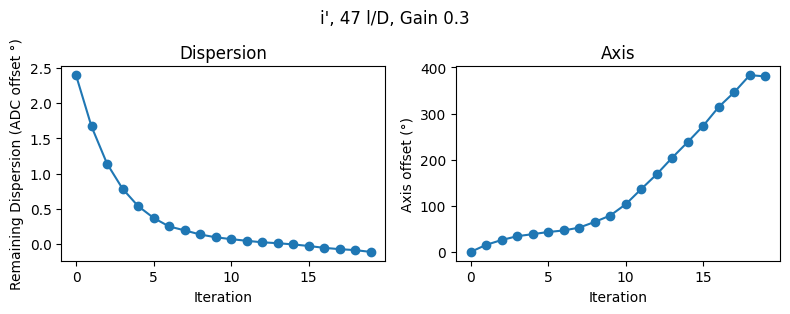

In [489]:
imshow_field(psf,ax=ax[1])
ax[1].set_title('After Correction')
fig.suptitle(f'Gain = {gain}')
plt.show()

fig, ax = plt.subplots(1,2,figsize=(8,3))
ax[0].plot(disp_tracker,'o-')
ax[0].set_title('Dispersion')
ax[0].set_xlabel('Iteration')
ax[0].set_ylabel('Remaining Dispersion (ADC offset °)')

ax[0].set_box_aspect(0.6)

ax[1].plot(ang_tracker,'o-')
ax[1].set_title('Axis')
ax[1].set_xlabel('Iteration')
ax[1].set_ylabel('Axis offset (°)')
ax[1].set_box_aspect(0.6)

fig.suptitle(f'i\', 47 l/D, Gain {gain}')
fig.tight_layout()
plt.show()

In [530]:
#only correcting the angle
ang_tracker = []

injected_disp = 0.1
injected_ang = 330

print(f'Overall Dispersion Angle: {injected_ang}°')

disp_x = np.cos(np.radians(injected_ang)) * injected_disp
disp_y = np.sin(np.radians(injected_ang)) * injected_disp

#assume adc orientation and dispersion orientation are 1:1
nominal_adc_axis = 0
gain = 0.5

adc_axis = nominal_adc_axis
ang_integrator = 0

for i in range(10):
    #plt.figure()
    ang_tracker.append(adc_axis)
    disp_x = np.cos(np.radians(injected_ang - adc_axis)) * injected_disp
    disp_y = np.sin(np.radians(injected_ang - adc_axis)) * injected_disp

    nominal_psf = PsfGen.noisy_psf(magnitude_x=disp_x,magnitude_y=disp_y,num_photons=1E9)
    est_x, est_y = ADC.speckles_dxdy(nominal_psf,plotted=False,printed=True)
    sq = np.sqrt(est_x**2+est_y**2)
    ang = np.degrees(np.arctan2(est_y,est_x))

    ang_offset = adc_axis - injected_ang

    print(f'estimated overall angle: {ang}°')
    print(f'estimated axis offset: {ang_offset}°')

    #ok, now we know how much the adc axis is offset from the real axis. we apply a gain, and move the adc towards the dispersion axis.
    #since we subtracted the angle fromt the adc axis, we know we are "short" by 39 degrees and we need to add to the adc axis

    ang_integrator += gain * ang_offset
    new_axis = nominal_adc_axis - ang_integrator
    print(f'new adc axis orientation {new_axis}\n')

    adc_axis = new_axis

Overall Dispersion Angle: 330°
least-squares solution: (9.000812160801711,-4.804009666995949)
Estimated dispersion direction -151.90979101466291°
Estimated dispersion magnitude 10.202604002637097
estimated overall angle: -28.090208985337103°
estimated axis offset: -330°
new adc axis orientation 165.0

least-squares solution: (-10.348755771017268,1.8748192873622758)
Estimated dispersion direction 169.73145463238333°
Estimated dispersion magnitude 10.517209390728551
estimated overall angle: 169.73145463238333°
estimated axis offset: -165.0°
new adc axis orientation 247.5

least-squares solution: (0.9216751899687441,10.377646670466717)
Estimated dispersion direction 84.92467740285244°
Estimated dispersion magnitude 10.418494880396729
estimated overall angle: 84.92467740285244°
estimated axis offset: -82.5°
new adc axis orientation 288.75

least-squares solution: (7.898406994813713,6.7130160398357495)
Estimated dispersion direction 40.36188369947488°
Estimated dispersion magnitude 10.36578

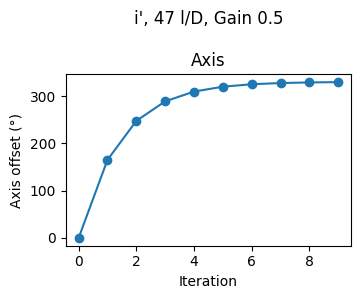

In [525]:
# imshow_field(psf,ax=ax)
# ax.set_title('After Correction')
# fig.suptitle(f'Gain = {gain}')
# plt.show()

fig, ax = plt.subplots(1,1,figsize=(8,3))

ax.plot(ang_tracker,'o-')
ax.set_title('Axis')
ax.set_xlabel('Iteration')
ax.set_ylabel('Axis offset (°)')
ax.set_box_aspect(0.6)

fig.suptitle(f'i\', 47 l/D, Gain {gain}')

fig.tight_layout()
plt.show()


In [544]:
#now we add in the magnitude correction. we also have to take into account the degeneracy between magnitudes and angles when they switch sign.
#version 1: we correct orientation first, then magnitude. this way we don't have to change the response slope every iteration.

ang_tracker = []
disp_tracker = []

injected_disp = 0.1
injected_ang = 90

print(f'Overall Dispersion Angle: {injected_ang}°')

disp_x = np.cos(np.radians(injected_ang)) * injected_disp
disp_y = np.sin(np.radians(injected_ang)) * injected_disp

#assume adc orientation and dispersion orientation are 1:1
nominal_adc_axis = 27
gain = 0.5

adc_axis = nominal_adc_axis
ang_integrator = 0

ang_offset = nominal_adc_axis - injected_ang
ang_counter = 0

while np.abs(ang_offset) > 0.5:
    #plt.figure()
    ang_tracker.append(adc_axis)
    disp_x = np.cos(np.radians(injected_ang - adc_axis)) * injected_disp
    disp_y = np.sin(np.radians(injected_ang - adc_axis)) * injected_disp

    nominal_psf = PsfGen.noisy_psf(magnitude_x=disp_x,magnitude_y=disp_y,num_photons=1E9)
    est_x, est_y = ADC.speckles_dxdy(nominal_psf,plotted=False,printed=True)
    sq = np.sqrt(est_x**2+est_y**2)
    ang = np.degrees(np.arctan2(est_y,est_x))

    ang_offset = adc_axis - injected_ang

    print(f'estimated overall angle: {ang}°')
    print(f'estimated axis offset: {ang_offset}°')

    #ok, now we know how much the adc axis is offset from the real axis. we apply a gain, and move the adc towards the dispersion axis.
    #since we subtracted the angle fromt the adc axis, we know we are "short" by 39 degrees and we need to add to the adc axis

    ang_integrator += gain * ang_offset
    new_axis = nominal_adc_axis - ang_integrator
    print(f'new adc axis orientation {new_axis}\n')

    adc_axis = new_axis
    ang_counter +=1

print(f'iterations to converge to the right orientation: {ang_counter}')

disp = injected_disp
shear_est = 0 
disp_counter = 0
print(f'\ndisp {disp} corresponds to shear of {injected_disp * m02*m00}')

while np.abs(disp) > 0.001:
    disp_tracker.append(disp)
    disp_x = np.cos(np.radians(injected_ang - adc_axis)) * disp
    disp_y = np.sin(np.radians(injected_ang - adc_axis)) * disp

    nominal_psf = PsfGen.noisy_psf(magnitude_x=disp_x,magnitude_y=disp_y,num_photons=1E9)
    est_x, est_y = ADC.speckles_dxdy(nominal_psf,plotted=False,printed=True)
    sq = np.sqrt(est_x**2+est_y**2)
    ang = np.degrees(np.arctan2(est_y,est_x))


    shear_est -= sign * m00 * sq
    print(f'est ADC shear angle: {shear_est}°')

    #integrate
    disp = injected_disp + gain * shear_est * 1/m00 * 1/m02 #deg * px/deg * arb./px
    print(f'new dispersion {disp}, corresponds to shear of {disp * m02*m00}\n')
    disp_counter += 1

print(f'iterations to converge to correct dispersion: {disp_counter}')

Overall Dispersion Angle: 90°
least-squares solution: (4.1463193064497785,8.611551275462912)
Estimated dispersion direction 64.28995525996929°
Estimated dispersion magnitude 9.557760153977766
estimated overall angle: 64.28995525996928°
estimated axis offset: -63°
new adc axis orientation 58.5

least-squares solution: (9.23571898854379,5.207273028447722)
Estimated dispersion direction 29.415126015791568°
Estimated dispersion magnitude 10.602556183682662
estimated overall angle: 29.41512601579156°
estimated axis offset: -31.5°
new adc axis orientation 74.25

least-squares solution: (10.556693359545669,2.842099740841243)
Estimated dispersion direction 15.06804822461506°
Estimated dispersion magnitude 10.932580007681878
estimated overall angle: 15.06804822461506°
estimated axis offset: -15.75°
new adc axis orientation 82.125

least-squares solution: (11.161674810638008,1.556985881803218)
Estimated dispersion direction 7.941170120971694°
Estimated dispersion magnitude 11.269746652634456
est

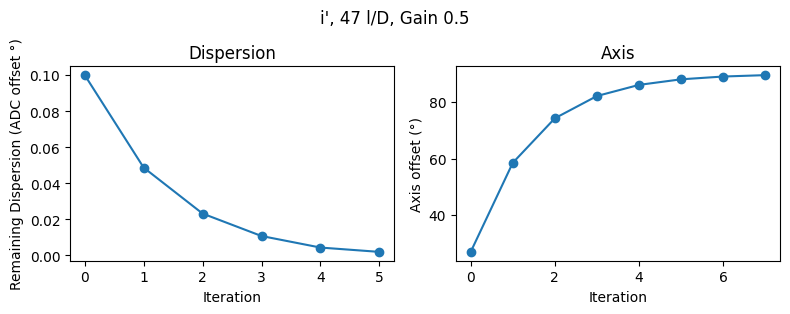

In [545]:
fig, ax = plt.subplots(1,2,figsize=(8,3))
ax[0].plot(disp_tracker,'o-')
ax[0].set_title('Dispersion')
ax[0].set_xlabel('Iteration')
ax[0].set_ylabel('Remaining Dispersion (ADC offset °)')

ax[0].set_box_aspect(0.6)

ax[1].plot(ang_tracker,'o-')
ax[1].set_title('Axis')
ax[1].set_xlabel('Iteration')
ax[1].set_ylabel('Axis offset (°)')
ax[1].set_box_aspect(0.6)

fig.suptitle(f'i\', 47 l/D, Gain {gain}')
fig.tight_layout()
plt.show()

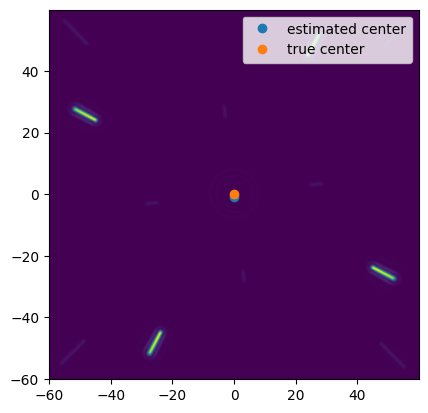

In [572]:
#now we just need this to work but if we don't know the true center of the image
#what if we average just the speckle positions to try and estimate the center? will that work? 
# - speckles 1 and 3 are so much fainter that i can't do a center of intensity between all the speckles i don't think, 
# but i could find the center of intensity of each speckle and then just take the average of all four of them equally weighted
# I already sort of do this in my slicing algorithm - i look at where the speckle should be, then i re-center the window on the center of intensity 
img = psf
extent = 40

def est_center(img,extent=40):

    cois = np.zeros((4,2))

    for i in range(4):
        speckle_number = i

        speckle_coords = np.array([[0, ADC.grating_freq * ADC.normalized_wavelength],[ADC.grating_freq * ADC.normalized_wavelength,0],[0, -ADC.grating_freq * ADC.normalized_wavelength],[-ADC.grating_freq * ADC.normalized_wavelength,0]])
        speckle_center = speckle_coords[speckle_number]
        rect = make_rotated_aperture(make_rectangular_aperture(size=(extent,extent), center=speckle_center), np.deg2rad(-ADC.grating_angle))(img.grid)

        speckle_img = rect * img

        #find the center of intensity of the speckle area and window the ORIGINAL image around that center
        center_of_intensity = np.array([sum(speckle_img*speckle_img.grid.x)/sum(speckle_img),sum(speckle_img*speckle_img.grid.y)/sum(speckle_img)])
        window_size=ADC.speckle_window
        new_img = ADC.window_field(img,[center_of_intensity[0],center_of_intensity[1]],window_size,window_size)

        coi = np.array([sum(new_img*new_img.grid.x)/sum(new_img),sum(new_img*new_img.grid.y)/sum(new_img)])

        cois[i,:] = center_of_intensity + coi

    overall_coi = np.mean(cois,axis=0)
    return overall_coi


imshow_field(img)
plt.plot(overall_coi[0],overall_coi[1],'o',label='estimated center')
plt.plot(0,0,'o',label='true center')
plt.legend()
plt.show()


[[ 25.75791167  46.95493217]
 [ 48.94846    -26.5977275 ]
 [-25.61485034 -48.38900759]
 [-48.97656047  24.44999877]]
[ 0.02874022 -0.89545104]


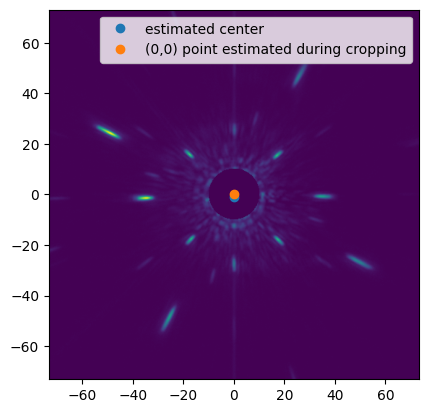

In [570]:
step = read_field('/Users/Katie/Documents/MagAO-X/Data/ADC/2025B/i_sparkles_counter_sat.fits')
for img in step:
    img -= np.median(img)

img = step[30]
img = ADC.crop_image(img,extent=512,mask_diam=20)
extent = 40

cois = np.zeros((4,2))

for i in range(4):
    speckle_number = i

    speckle_coords = np.array([[0, ADC.grating_freq * ADC.normalized_wavelength],[ADC.grating_freq * ADC.normalized_wavelength,0],[0, -ADC.grating_freq * ADC.normalized_wavelength],[-ADC.grating_freq * ADC.normalized_wavelength,0]])
    speckle_center = speckle_coords[speckle_number]
    rect = make_rotated_aperture(make_rectangular_aperture(size=(extent,extent), center=speckle_center), np.deg2rad(-ADC.grating_angle))(img.grid)

    speckle_img = rect * img

    #find the center of intensity of the speckle area and window the ORIGINAL image around that center
    center_of_intensity = np.array([sum(speckle_img*speckle_img.grid.x)/sum(speckle_img),sum(speckle_img*speckle_img.grid.y)/sum(speckle_img)])
    window_size=ADC.speckle_window
    new_img = ADC.window_field(img,[center_of_intensity[0],center_of_intensity[1]],window_size,window_size)

    coi = np.array([sum(new_img*new_img.grid.x)/sum(new_img),sum(new_img*new_img.grid.y)/sum(new_img)])

    cois[i,:] = center_of_intensity + coi

print(cois)
overall_coi = np.mean(cois,axis=0)
print(overall_coi)

imshow_field(img)
plt.plot(overall_coi[0],overall_coi[1],'o',label='estimated center')
plt.plot(0,0,'o',label='(0,0) point estimated during cropping')
plt.legend()
plt.show()



In [575]:
#now do control using that as the (0,0) point
#now we add in the magnitude correction. we also have to take into account the degeneracy between magnitudes and angles when they switch sign.
#version 1: we correct orientation first, then magnitude. this way we don't have to change the response slope every iteration.

ang_tracker = []
disp_tracker = []

injected_disp = 0.1
injected_ang = 90

print(f'Overall Dispersion Angle: {injected_ang}°')

disp_x = np.cos(np.radians(injected_ang)) * injected_disp
disp_y = np.sin(np.radians(injected_ang)) * injected_disp

#assume adc orientation and dispersion orientation are 1:1
nominal_adc_axis = 27
gain = 0.3

adc_axis = nominal_adc_axis
ang_integrator = 0

ang_offset = nominal_adc_axis - injected_ang
ang_counter = 0

while np.abs(ang_offset) > 0.5:
    #plt.figure()
    ang_tracker.append(adc_axis)
    disp_x = np.cos(np.radians(injected_ang - adc_axis)) * injected_disp
    disp_y = np.sin(np.radians(injected_ang - adc_axis)) * injected_disp

    psf = PsfGen.noisy_psf(magnitude_x=disp_x,magnitude_y=disp_y,num_photons=1E9)
    est_x, est_y = ADC.speckles_dxdy(psf,plotted=False,printed=True)
    center = est_center(psf)
    print(f'estimated center {center}')
    est_x -= center[0]
    est_y -= center[1]

    sq = np.sqrt(est_x**2+est_y**2)
    ang = np.degrees(np.arctan2(est_y,est_x))

    ang_offset = adc_axis - injected_ang

    print(f'estimated overall angle: {ang}°')
    print(f'estimated axis offset: {ang_offset}°')

    #ok, now we know how much the adc axis is offset from the real axis. we apply a gain, and move the adc towards the dispersion axis.
    #since we subtracted the angle fromt the adc axis, we know we are "short" by 39 degrees and we need to add to the adc axis

    ang_integrator += gain * ang_offset
    new_axis = nominal_adc_axis - ang_integrator
    print(f'new adc axis orientation {new_axis}\n')

    adc_axis = new_axis
    ang_counter +=1

print(f'iterations to converge to the right orientation: {ang_counter}')

disp = injected_disp
shear_est = 0 
disp_counter = 0
print(f'\ndisp {disp} corresponds to shear of {injected_disp * m02*m00}')

while np.abs(disp) > 0.001:
    disp_tracker.append(disp)
    disp_x = np.cos(np.radians(injected_ang - adc_axis)) * disp
    disp_y = np.sin(np.radians(injected_ang - adc_axis)) * disp

    psf = PsfGen.noisy_psf(magnitude_x=disp_x,magnitude_y=disp_y,num_photons=1E9)
    est_x, est_y = ADC.speckles_dxdy(psf,plotted=False,printed=True)
    sq = np.sqrt(est_x**2+est_y**2)
    ang = np.degrees(np.arctan2(est_y,est_x))


    shear_est -= sign * m00 * sq
    print(f'est ADC shear angle: {shear_est}°')

    #integrate
    disp = injected_disp + gain * shear_est * 1/m00 * 1/m02 #deg * px/deg * arb./px
    print(f'new dispersion {disp}, corresponds to shear of {disp * m02*m00}\n')
    disp_counter += 1

print(f'iterations to converge to correct dispersion: {disp_counter}')

Overall Dispersion Angle: 90°
least-squares solution: (4.935528083719259,9.42077138792712)
Estimated dispersion direction 62.350024021509704°
Estimated dispersion magnitude 10.635335961255185
estimated center [0.08797881 0.09580458]
estimated overall angle: 62.53250182792204°
estimated axis offset: -63°
new adc axis orientation 45.9

least-squares solution: (7.955672565082677,7.293516349789086)
Estimated dispersion direction 42.513642259405856°
Estimated dispersion magnitude 10.792965612261067
estimated center [0.0826565  0.09195599]
estimated overall angle: 42.449602255942715°
estimated axis offset: -44.1°
new adc axis orientation 59.129999999999995

least-squares solution: (9.72083112469232,5.360997520406301)
Estimated dispersion direction 28.876550970790746°
Estimated dispersion magnitude 11.10111941060853
estimated center [0.07750046 0.05199673]
estimated overall angle: 28.834367001376222°
estimated axis offset: -30.870000000000005°
new adc axis orientation 68.39099999999999

least

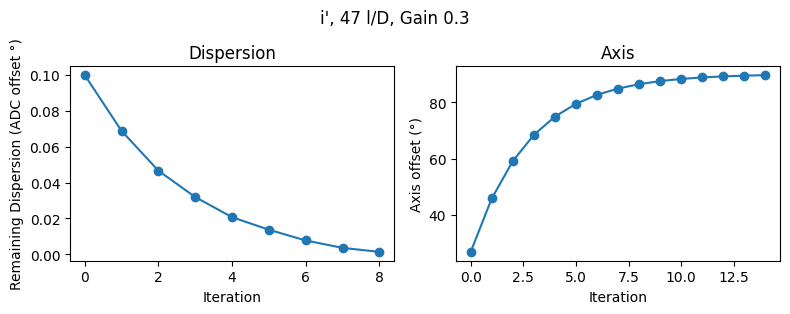

In [576]:
fig, ax = plt.subplots(1,2,figsize=(8,3))
ax[0].plot(disp_tracker,'o-')
ax[0].set_title('Dispersion')
ax[0].set_xlabel('Iteration')
ax[0].set_ylabel('Remaining Dispersion (ADC offset °)')

ax[0].set_box_aspect(0.6)

ax[1].plot(ang_tracker,'o-')
ax[1].set_title('Axis')
ax[1].set_xlabel('Iteration')
ax[1].set_ylabel('Axis offset (°)')
ax[1].set_box_aspect(0.6)

fig.suptitle(f'i\', 47 l/D, Gain {gain}')
fig.tight_layout()
plt.show()